[![Open In Colab](https://colab.research.google.com/assets/colab-badge.svg)](https://colab.research.google.com/github/QMCSoftware/QMCSoftware/blob/develop/demos/pymc_model.ipynb)

In [1]:
# @title Execute this cell to install dependencies
try:
  import google.colab
  IN_COLAB = True
except ImportError:
  IN_COLAB = False
if IN_COLAB:
  !pip install -q qmcpy
  !tmp=$(mktemp) && if { apt-get update -qq && DEBIAN_FRONTEND=noninteractive apt-get install -y -qq --no-install-recommends texlive-latex-base texlive-fonts-recommended texlive-latex-extra cm-super dvipng; } >"$tmp" 2>&1; then rm -f "$tmp"; else status=$?; cat "$tmp"; rm -f "$tmp"; exit $status; fi


In [2]:
import matplotlib.pyplot as plt
import numpy as np
from scipy.stats import norm, describe
from IPython.display import Markdown, display

from qmcpy import DigitalNetB2
from qmcpy.util import DimensionError
import pymc as pm
from qmcpy import PyMCWrapper

plt.style.use("seaborn-v0_8-whitegrid")
plt.rcParams['text.usetex'] = True

def show_table(headers, rows):
    """Render a compact table from the existing computed results."""
    lines = [
        "| " + " | ".join(headers) + " |",
        "| " + " | ".join(["---"] * len(headers)) + " |",
    ]
    lines.extend("| " + " | ".join(map(str, row)) + " |" for row in rows)
    display(Markdown("\n".join(lines)))


# PyMC Model TrueMeasure in QMCPy

[PyMC](https://www.pymc.io/), a popular Probabilistic Programming Language (PPL), allows specifiying statistical models in an easy to use and familiar syntax. A PyMC `Model` combines several probability distributions and other operations into one joint distribution of random variables. 
`PyMCWrapper` allows using a PyMC `Model` as a QMCPy TrueMeasure.

This tutorial shows basic examples of constructing and computing expectations with PyMC models, and covers limitations and workarounds around these limitations.

We state limitations an gotchas here so the reader can easily find them below:
- The samples correspond strictly to the random variables, **not** to any transformation of them or any Deterministics in the model.
- Multivariate distributions are not supported (see workaround below).
- Only sampling from the prior distribution is supported. Posterior sampling takes extra steps shown below.
- Discrete and some other distributions are currently not supported as their icdf is not currently defined by PyMC.

## 1. Basic Use

For example, consider
$$
X\sim \,N(0.0,1.0).
$$

In [3]:
with pm.Model() as model:
    x = pm.Normal("x", mu=0.0, sigma=1.0)

tm_normal = PyMCWrapper(DigitalNetB2(1, seed=7), model)
samples = tm_normal(2**12)

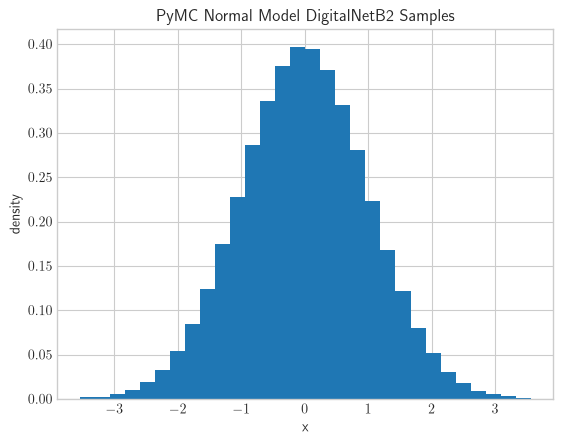

In [4]:
plt.hist(samples, density=True, bins=30);
plt.title("PyMC Normal Model DigitalNetB2 Samples");
plt.xlabel("x");
plt.ylabel("density");

As we can see, the `PyMCWrapper` is initialized with
```
PyMCWrapper(discrete_distribution, model)
```
where the `discrete_distribution` must have the right number of dimensions, according to the distributions in the pymc model and their shapes.
If we use a distribution with the wrong dimension we get **an error telling us the right dimension to use**:

In [5]:
try:
    tm_normal = PyMCWrapper(DigitalNetB2(2, seed=7), model) # intentional error, shown below
except DimensionError as error:
    print(f"Caught Error: [\033[1m{str(error)}]")

Caught Error: [sampler dimension 2 must match the model joint samples dimension 1.]


The error message is telling us to use a sampler with 1 dimension for this model.

## 2. Hierarchical Specification of Student's t-distribution

Here we show a more realistic use of this feature and compare results with MCMC.  
A Student's t-distributed $X$ can be written as
$$
\begin{align*}
s \sim & \chi^2(\nu)\\
X \sim & N(0,\sqrt{\nu/s})
\end{align*}
$$

We show this hierarchical construction gives the same results as the marginalized one by comparing samples.

In [6]:
nu = 5.0
with pm.Model() as tstudent_normal_model:
  s = pm.ChiSquared("s", nu=nu)
  x = pm.Normal("x", mu=0.0, sigma=pm.math.sqrt(nu/s))

# take samples using MCMC
with tstudent_normal_model:
  idata = pm.sample(draws=2048, tune=1000)
mcmc_s_samples = np.asarray(idata.posterior["s"]).ravel()
mcmc_x_samples = np.asarray(idata.posterior["x"]).ravel()

Initializing NUTS using jitter+adapt_diag...
Multiprocess sampling (4 chains in 4 jobs)
NUTS: [s, x]


Output()

Sampling 4 chains for 1_000 tune and 2_048 draw iterations (4_000 + 8_192 draws total) took 2 seconds.


In [7]:
# take samples using QMC
tstudent_normal = PyMCWrapper(DigitalNetB2(2, seed=7), tstudent_normal_model)
qmc_samples = tstudent_normal(2**13)
qmc_s_samples = qmc_samples[...,0]
qmc_x_samples = qmc_samples[...,1]

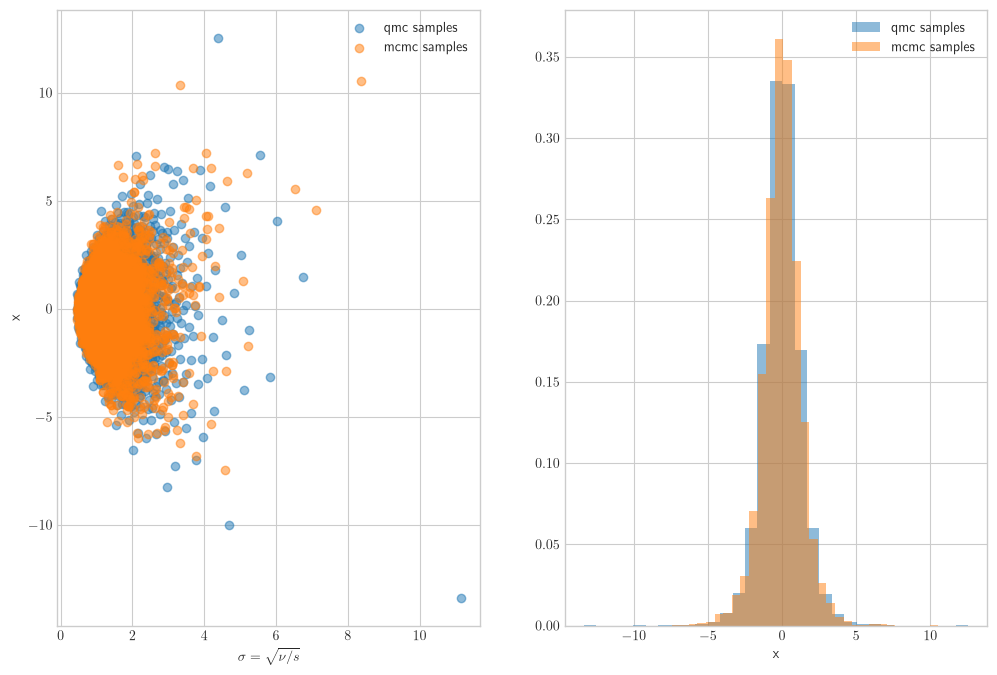

In [8]:
fig, ax = plt.subplots(1, 2, figsize=(12, 8))
ax[0].scatter(np.sqrt(nu/qmc_s_samples), qmc_x_samples, alpha=0.5, label="qmc samples");
ax[0].scatter(np.sqrt(nu/mcmc_s_samples), mcmc_x_samples, label="mcmc samples", alpha=0.5)
ax[0].legend();
ax[0].set_xlabel(r"$\sigma=\sqrt{\nu/s}$");
ax[0].set_ylabel("x");

ax[1].hist(qmc_x_samples, bins=31, alpha=0.5, label="qmc samples", density=True);
ax[1].hist(mcmc_x_samples, bins=31, label="mcmc samples", alpha=0.5, density=True)
ax[1].legend();
ax[1].set_xlabel("x");

As shown in the plots, the quasi Monte Carlo samples are more uniformly spread out, with the Markov Chain Monte Carlo samples being more concentrated around the mode. To verify the results and compare with MCMC we can compute known statistics of this distribution and compare:

In [9]:
qmc_results = describe(qmc_x_samples)
mcmc_results = describe(mcmc_x_samples)
kurtosis = np.inf if (2< nu <= 4) else (6/(nu-4))
exact_results = {"mean": 0.0, "variance": nu/(nu-2), "skewness": 0.0, "kurtosis": kurtosis}
rows = ["mean", "variance", "skewness", "kurtosis"]
show_table(
    ["Type"]+ ["#samples"]+[r.capitalize() for r in rows],
    [
    ["Exact"]+["NA"]+[exact_results[r] for r in rows],
    ["MCMC"]+[mcmc_results.nobs]+[getattr(mcmc_results,r) for r in rows],
    ["QMC"]+[qmc_results.nobs]+[getattr(qmc_results, r) for r in rows]
    ]
)

| Type | #samples | Mean | Variance | Skewness | Kurtosis |
| --- | --- | --- | --- | --- | --- |
| Exact | NA | 0.0 | 1.6666666666666667 | 0.0 | 6.0 |
| MCMC | 8192 | -0.008381756236782577 | 1.6951604478800635 | 0.08343653284606943 | 3.2468850979405337 |
| QMC | 8192 | -0.0006265435610923478 | 1.6721966951019118 | -0.07427369019956372 | 5.036693471548967 |

We can see that estimation with QMC is at least as precise at the same number of samples.

## 3. Multivariate Distributions

Multivariate distributions in PyMC do not define an inverse CDF, thus this class raises an exception if we try to use them directly:

In [10]:
#### icdf NOT IMPLEMENTED
with pm.Model() as model:
  x = pm.MvNormal("x", mu=0.0, cov=np.eye(2))

try:
    PyMCWrapper(DigitalNetB2(2, seed=7), model)
except NotImplementedError as error:
    print(f"Caught Error: [\033[1m{str(error)[:49]}...]")

Caught Error: [Inverse CDF method not implemented for MvNormalRV...]


To work around this, we need to define our own multivariate distribution using i.i.d distributions. 
The model is defined with the i.i.d variables, which can be:
- sampled and transformed into the dependent joint distribution
- transformed **within the model** and used as an **input to other distributions**

In [11]:
### equivalent 
def mv_normal_from_iid(x, mu, cov_chol):
    return mu + x @ cov_chol.T
    
with pm.Model() as model:
    cov = np.array([[1, 0.8],[0.8,1]])
    cov_chol = np.linalg.cholesky(cov)
    mu = np.array([-2, 2])
    x = pm.Normal("x", mu=0.0, sigma=np.ones_like(np.diag(cov)))
    ### we can also do distributions that depend on `x`.
    ### here we show a linear regression example
    # mu_y = mv_normal_from_iid(x, mu, cov_chol) @ beta 
    # y = pm.Normal("y" mu=mu_y, sigma=np.diag(2))

# take samples using MCMC
with model:
    idata = pm.sample(draws=1000, tune=1000)
mcmc_x_samples = np.asarray(idata.posterior["x"]).reshape(-1,2)
mcmc_x_samples = mv_normal_from_iid(mcmc_x_samples, mu, cov_chol)

Initializing NUTS using jitter+adapt_diag...
Multiprocess sampling (4 chains in 4 jobs)
NUTS: [x]


Output()

Sampling 4 chains for 1_000 tune and 1_000 draw iterations (4_000 + 4_000 draws total) took 1 seconds.


In [12]:
# take samples using QMC
mv_normal = PyMCWrapper(DigitalNetB2(2, seed=7), model)
qmc_samples = mv_normal(2**14)
qmc_samples = mv_normal_from_iid(qmc_samples, mu, cov_chol)

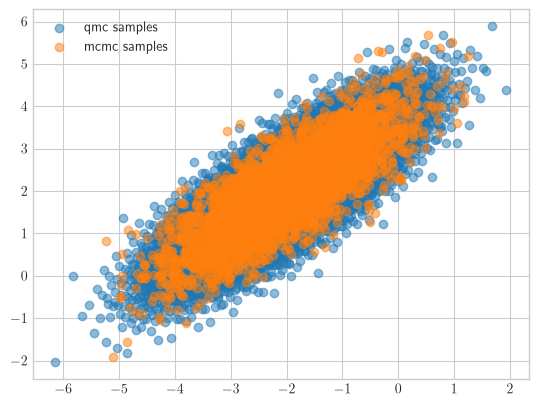

In [13]:
plt.figure()
plt.scatter(qmc_samples[:,0], qmc_samples[:,1], alpha=0.5, label="qmc samples");
plt.scatter(mcmc_x_samples[:,0], mcmc_x_samples[:,1], label="mcmc samples", alpha=0.5)
plt.legend();

The QMC samples are visibly more representative of the distribution.

## 4. Sampling Prior Vs Posterior Models

PyMC provides utilities to sample the model **prior** (`sample_prior_predictive`), **posterior** (`sample`) and **posterior predictive** (`sample_posterior_predictive`) distributions.
PyMCWrapper, on the other hand, **always samples the prior** distribution. In order to sample from the posterior, further processing of the model must be performed.
Such options include:
- Fitting an approximate distribution to the posteior (Variational Inference, i.e. `pymc.fit`), and sampling from that. 
- Condition Random variables of interest to point values such as posterior mode and sample the resulting model (`pymc.do`).

This is demonstrated below with more complicated model examples taken from [PosteriorDB](https://github.com/stan-dev/posteriordb/tree/master/posterior_database/models/pymc).

### Arma autoregression model

In [14]:
# download data
import urllib.request

url = "https://github.com/stan-dev/posteriordb/raw/refs/heads/master/posterior_database/data/data/arma.json.zip"
output_filename = "arma.json.zip"

# Downloads the file and saves it locally
urllib.request.urlretrieve(url, output_filename)
print(f"Downloaded {output_filename} successfully!")
!wget 
!unzip -o arma.json.zip  # overwrite existing files

Downloaded arma.json.zip successfully!
wget: missing URL
Usage: wget [OPTION]... [URL]...

Try `wget --help' for more options.
Archive:  arma.json.zip
  inflating: arma.json               


In [15]:
## https://github.com/stan-dev/posteriordb/blob/master/posterior_database/models/pymc/arma11.py
import pytensor
import pytensor.tensor as pt
import json
with open("arma.json", "r") as f:
    data_dict = json.load(f)
data_dict["y"] = np.asarray(data_dict["y"])
def arma(data):
    y_obs = data["y"]  # Observed series
    up_to = data["T"]  # Timesteps
    with pm.Model() as pymc_model:
        mu = pm.Normal(
            "mu", mu=0, sigma=10
        )  # mean coefficient
        phi = pm.Normal(
            "phi", mu=0, sigma=2
        ) # autoregressive coef
        theta = pm.Normal(
            "theta", mu=0, sigma=2
        ) # moving average
        sigma = pm.HalfCauchy(
            "sigma", beta=2.5
        ) # noise scale

        # scan variables
        y = pt.as_tensor_variable(y_obs)
        y_hat0 = mu + phi * mu
        err0 = y[0] - y_hat0
        outputs_info = [y_hat0, err0, y[0]]

        def step(curr_obs, prev_pred, prev_err, prev_obs, mu, phi, theta):
            y_hat = mu + phi * prev_obs + theta * prev_err
            new_err = curr_obs - y_hat
            return [y_hat, new_err, curr_obs]

        [predictions, _, _] = pytensor.scan(fn=step,
                                              outputs_info=outputs_info,    
                                              sequences=y[1:],              
                                              non_sequences=[mu, phi, theta], return_updates=False)

        # concatenating predictions
        y_hat0_vec = y_hat0.dimshuffle("x")
        final_predictions = pt.concatenate([y_hat0_vec, predictions])
        pm.Normal("y", mu=final_predictions, sigma=sigma, observed=y)

    return pymc_model
_arma = arma(data_dict)
_arma

   mu ~ Normal(0, 10)
  phi ~ Normal(0, 2)
theta ~ Normal(0, 2)
sigma ~ HalfCauchy(2.5)
    y ~ Normal(f(mu, theta, phi), sigma)

#### Prior Sampling

Prior sampling proceeds as in the basic examples. Each random variable is sampled with inverse transform sampling as usual.  
"Observed" random variables are treated as free variables.  
Below the model variables are sampled and plotted. In some cases the plots are restricted due to the high variability in the prior predictive samples.

In [16]:
qmc_arma = PyMCWrapper(DigitalNetB2(204, seed=7), _arma)
qmc_samples = qmc_arma(2**13)
mu_samples = qmc_samples[:,0]
phi_samples = qmc_samples[:,1]
theta_samples = qmc_samples[:,2]
sigma_samples = qmc_samples[:,3]
y_samples = qmc_samples[:, 4:]

In [17]:
with _arma:
    idata = pm.sample_prior_predictive()
idata

Sampling: [mu, phi, sigma, theta, y]


<xarray.DataTree>
Group: /
├── Group: /prior
│       Dimensions:  (chain: 1, draw: 500)
│       Coordinates:
│         * chain    (chain) int64 8B 0
│         * draw     (draw) int64 4kB 0 1 2 3 4 5 6 7 ... 493 494 495 496 497 498 499
│       Data variables:
│           theta    (chain, draw) float64 4kB -2.062 0.5556 -1.379 ... -0.8337 0.5647
│           phi      (chain, draw) float64 4kB -0.1363 1.585 1.372 ... 4.14 -0.2603
│           mu       (chain, draw) float64 4kB -1.216 -2.171 -8.595 ... -10.02 10.64
│           sigma    (chain, draw) float64 4kB 0.5907 0.4846 0.07181 ... 0.0997 1.294
│       Attributes:
│           created_at:                 2026-10-22T12:12:07.386868+00:00
│           creation_library:           ArviZ
│           creation_library_version:   1.1.0
│           creation_library_language:  Python
│           inference_library:          pymc
│           inference_library_version:  6.0.1
│           sample_dims:                ['chain', 'draw']
├── Group: /prior_predictive
│       Dimensions:  (chain: 1, draw: 500, y_dim_0: 200)
│       Coordinates:
│         * chain    (chain) int64 8B 0
│         * draw     (draw) int64 4kB 0 1 2 3 4 5 6 7 ... 493 494 495 496 497 498 499
│         * y_dim_0  (y_dim_0) int64 2kB 0 1 2 3 4 5 6 7 ... 193 194 195 196 197 198 199
│       Data variables:
│           y        (chain, draw, y_dim_0) float64 800kB -1.987 -4.895 ... 7.063 8.748
│       Attributes:
│           created_at:                 2026-10-22T12:12:07.389724+00:00
│           creation_library:           ArviZ
│           creation_library_version:   1.1.0
│           creation_library_language:  Python
│           inference_library:          pymc
│           inference_library_version:  6.0.1
│           sample_dims:                ['chain', 'draw']
└── Group: /observed_data
        Dimensions:  (y_dim_0: 200)
        Coordinates:
          * y_dim_0  (y_dim_0) int64 2kB 0 1 2 3 4 5 6 7 ... 193 194 195 196 197 198 199
        Data variables:
            y        (y_dim_0) float64 2kB 0.732 0.6624 0.9459 ... 0.6364 0.6335 0.7815
        Attributes:
            created_at:                 2026-10-22T12:12:07.390855+00:00
            creation_library:           ArviZ
            creation_library_version:   1.1.0
            creation_library_language:  Python
            inference_library:          pymc
            inference_library_version:  6.0.1
            sample_dims:                []

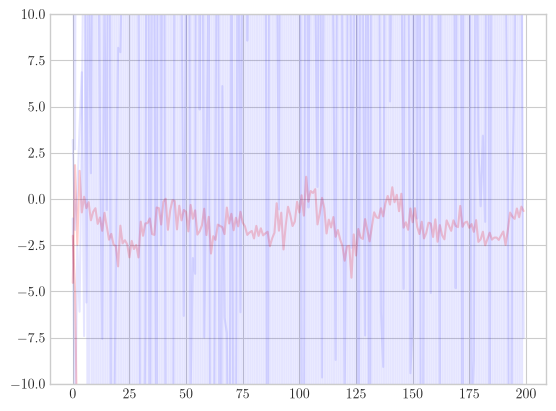

In [18]:
T = 200
plt.figure()
for i in range(3):
    plt.plot(np.asarray(idata.prior_predictive["y"]).reshape(-1,200)[i,:T], alpha=0.2, color="r")
    plt.plot(y_samples[i*2,:T], alpha=0.1, color="b")
plt.ylim(-10, 10);

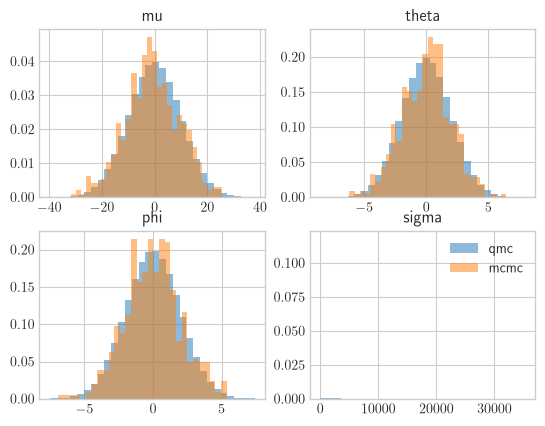

In [19]:
tonp = lambda x: np.asarray(x).ravel()
fig, ax = plt.subplots(2,2)
ax[0,0].set_title("mu")
ax[0,0].hist(mu_samples, bins=30, alpha=0.5, label="qmc", density=True);
ax[0,0].hist(tonp(idata.prior["mu"]), bins=30, alpha=0.5, label="mcmc", density=True);
ax[1,0].set_title("phi")
ax[1,0].hist(phi_samples, bins=30, alpha=0.5, label="qmc", density=True);
ax[1,0].hist(tonp(idata.prior["phi"]), bins=30, alpha=0.5, label="mcmc", density=True);
ax[0,1].set_title("theta")
ax[0,1].hist(theta_samples, bins=30, alpha=0.5, label="qmc", density=True);
ax[0,1].hist(tonp(idata.prior["theta"]), bins=30, alpha=0.5, label="mcmc", density=True);
ax[1,1].set_title("sigma")
ax[1,1].hist(sigma_samples, alpha=0.5, label="qmc", density=True);
ax[1,1].hist(tonp(idata.prior["sigma"]), alpha=0.5, label="mcmc", density=True);
plt.legend();

#### Posterior Sampling

To sample from the posterior we need to estimate it, create a model for it, and then QMCPy can be used to sample that model.
The simplest way to do this would be to first obtain an estimated mode for the model conditioned on the data.
This point estimate model can be constructed with `pymc.do` and sampled:

In [20]:
# conditioned model:
point_estimate_arma = pm.do(arma(data_dict), {"mu": 0.1, "phi": 0.05, "theta": 0.1, "sigma":0.2})

In [21]:
# PyMC MCMC sampling
with point_estimate_arma:
    # In the conditioned model, the prior predictive is equivalent to
    # the posterior predictive, because the "prior" here is now a point mass
    # that we set at the posterior mode
    idata_y = pm.sample_prior_predictive()

Sampling: [y]


In [22]:
# QMC sampling:
qmc_point_estimate_arma = PyMCWrapper(DigitalNetB2(200, seed=7), point_estimate_arma)
qmc_point_samples = qmc_point_estimate_arma(2**13)
y_samples = qmc_point_samples

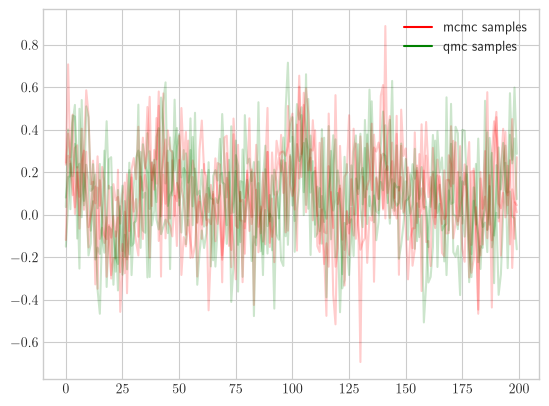

In [23]:
import matplotlib
T = 200
plt.figure()
for i in range(3):
    plt.plot(np.asarray(idata_y.prior_predictive["y"]).reshape(-1,200)[i,:T], alpha=0.2, color="r", label="mcmc samples")
    plt.plot(y_samples[i*2,:T], alpha=0.2, color="g", label="qmc samples")
    
legend_handles = [
    # A custom solid line
    matplotlib.lines.Line2D([0], [0], color='red', label='mcmc samples'),
    # A dashed line with a marker
    matplotlib.lines.Line2D([0], [0], color='green', label='qmc samples')
]

# 2. Pass your custom handles directly into the legend
plt.legend(handles=legend_handles, loc='upper right');

Note how the conditioned model has no "free random variables", with only `y` remaining.  
Accordingly the sampler dimensionality we used was 200 for the 200 `y` time steps.

In [24]:
point_estimate_arma.free_RVs

[]

In [25]:
point_estimate_arma.basic_RVs

[y]

The above method can be combined with the prior or other sampling to construct many such "point models" and sample each of them  
to obtain an overall posterior distribution. We will not demonstrate this here.

### Variational Approximation sampling

A second way to sample from the posterior for this model is to fit a variational estimate of the posterior and sample that.  
This is currently not directly supported, but can be rolled out by representing the results of variational inference in a `Model` object.
We demonstrate here for a simple regression model using the PyMC `fit` method. We need to convert the resulting `Approximation` object to a `Model` which `PyMCWrapper` can wrap and sample from:

In [26]:
# define model and observations
with pm.Model() as observed_normal_model:
    mu = pm.Normal("mu", mu=0.0, sigma=10.0)
    x = pm.Normal("x", mu=mu, sigma=0.3, observed=np.ones(10)*0.1)
with observed_normal_model:
    normal_mcmc_idata = pm.sample()
with observed_normal_model:
    normal_mcmc_idata_posterior = pm.sample_posterior_predictive(normal_mcmc_idata)
with observed_normal_model:
    VI_normal = pm.ADVI().fit()

########### extract VI Model
# Extract the unconstrained mean and standard deviation arrays
# (We use .eval() because these attributes are PyTensor symbolic variables)
flat_means = VI_normal.mean.eval()
flat_stds = VI_normal.std.eval()

# Map the flat arrays back to individual model variables using approx.ordering
fitted_gaussians = {}

for var_name, (_, slice_obj, _, _) in VI_normal.ordering.items():
    fitted_gaussians[var_name] = {
        "mean": flat_means[slice_obj],
        "std": flat_stds[slice_obj]
    }

with pm.Model() as VI_model:
    mu = pm.Normal("mu", mu=fitted_gaussians["mu"]["mean"], sigma=fitted_gaussians["mu"]["std"]) # VI posterior
    x = pm.Normal("x", mu=mu, sigma=0.3, observed=np.ones(10)*0.1) # same as original

Initializing NUTS using jitter+adapt_diag...
Multiprocess sampling (4 chains in 4 jobs)
NUTS: [mu]


Output()

Sampling 4 chains for 1_000 tune and 1_000 draw iterations (4_000 + 4_000 draws total) took 2 seconds.
Sampling: [x]


Output()

Output()

Finished [100%]: Average Loss = 2.2036


Here we wrap the new model and compare the samples with the MCMC samples from the original model, including the posterior predictive samples.  
Note how the `x` and `mu` samples are not centered around the origin, as expected.

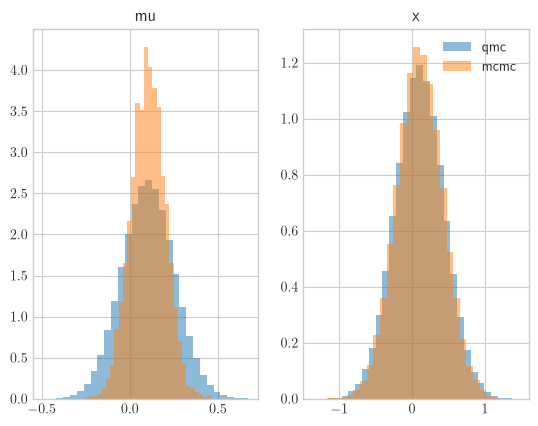

In [27]:
qmc_posterior = PyMCWrapper(DigitalNetB2(11, seed=7), VI_model)
qmc_samples = qmc_posterior(2**13)
qmc_mu_samples = qmc_samples[:,0]
qmc_x_samples = qmc_samples[:,1:].ravel()

tonp = lambda x: np.asarray(x).ravel()
fig, ax = plt.subplots(1,2)
ax[0].set_title("mu")
ax[0].hist(qmc_mu_samples, bins=30, alpha=0.5, label="qmc", density=True);
ax[0].hist(tonp(normal_mcmc_idata.posterior["mu"]), bins=30, alpha=0.5, label="mcmc", density=True);
ax[1].set_title("x")
ax[1].hist(qmc_x_samples, bins=30, alpha=0.5, label="qmc", density=True);
ax[1].hist(tonp(normal_mcmc_idata_posterior.posterior_predictive["x"]), bins=30, alpha=0.5, label="mcmc", density=True);
plt.legend();

## 5. Limitation - Model With Discrete Components

Here we demonstrate some of the limitations of `PyMCWrapper` that come from the incomplete implementation of `icdf` in PyMC itself.  
Generally as of PyMC `6.0.1` some discrete distributions and Dirichlet distribution, and possibly others, are missing such an implementation.

In [34]:
observations = np.concat([1+np.random.randn(5)/10, -1+np.random.randn(5)/10])
n_components = 2

with pm.Model() as gauss_mix:
    mu = pm.Normal(
        "mu",
        mu=observations.mean(),
        sigma=10,
        shape=n_components,
        transform=pm.distributions.transforms.ordered
    )
    sigma = pm.HalfNormal("sigma", sigma=10, shape=n_components)
    weights = pm.Dirichlet("w", np.ones(n_components))

    y = pm.NormalMixture("y", w=weights, mu=mu, sigma=sigma, observed=observations)

with gauss_mix:
    idata = pm.sample(initvals={"mu": [-0.7, 0.7]})
    idata_predictive = pm.sample_posterior_predictive(idata)

Initializing NUTS using jitter+adapt_diag...
Multiprocess sampling (4 chains in 4 jobs)
NUTS: [mu, sigma, w]


Output()

Sampling 4 chains for 1_000 tune and 1_000 draw iterations (4_000 + 4_000 draws total) took 3 seconds.
There were 20 divergences after tuning. Increase `target_accept` or reparameterize.
Sampling: [y]


Output()

<>:6: SyntaxWarning: invalid escape sequence '\m'
<>:6: SyntaxWarning: invalid escape sequence '\m'
/home/lior/temp/ipykernel_1160944/989850384.py:6: SyntaxWarning: invalid escape sequence '\m'
  plt.title("$\mu$ draws");


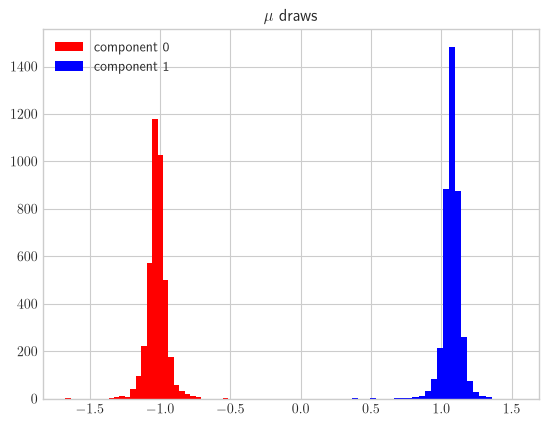

In [35]:
mu = np.asarray(idata.posterior["mu"]).reshape(-1, 2)
plt.figure()
plt.hist(mu[:,0], bins=30, label="component 0", color="red")
plt.hist(mu[:,1], bins=30, label="component 1", color="blue");
plt.legend();
plt.title("$\mu$ draws");

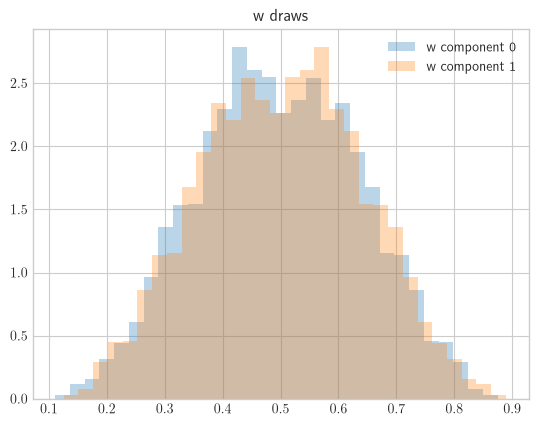

In [36]:
w = np.asarray(idata.posterior["w"]).reshape(-1,2)
plt.figure()
plt.hist(w[:,0], bins=30, label="w component 0", density=True, alpha=0.3)
plt.hist(w[:,1], bins=30, label="w component 1", density=True, alpha=0.3)
plt.legend();
plt.title("w draws");

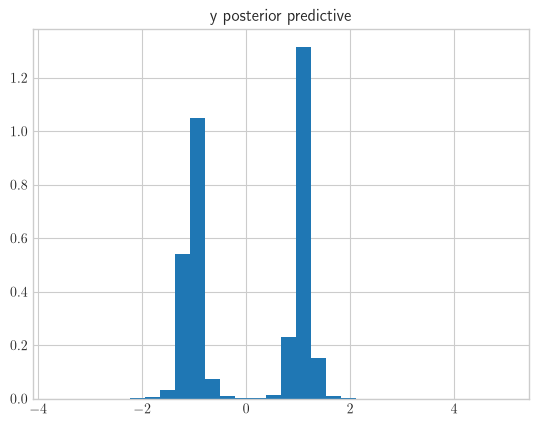

In [37]:
y = np.asarray(idata_predictive.posterior_predictive["y"]).ravel()
plt.figure()
plt.hist(y, bins=30, density=True)
plt.title("y posterior predictive");

In [38]:
try:
    qmcpy_mixture = PyMCWrapper(DigitalNetB2(13), gauss_mix)
except NotImplementedError as error:
    print(f"Caught Error: [\033[1m{str(error)[:51]}...]")

Caught Error: [Inverse CDF method not implemented for dirichlet_rv...]
